# Week 10 — Phase 3 dataset generation (L1 + L2, three energies)

Produces the labelled dataset for Phase 4: states in the Earth–Moon CR3BP with a
continuous regression target, **distance to the nearest quasi-periodic invariant
torus**, plus a thresholded binary label. Generate C, report B.

**Why the label is geometric, not dynamical.** These tori are strongly partially
hyperbolic — R_u = 146.32 on L2 halo #29 — so integrator error reaches O(1) after
~4 stroboscopic periods. Every forward-time indicator (NAFF, weighted Birkhoff,
FLI, MEGNO) needs one to two orders of magnitude more than that. The tori are
computable but not observable. `torus_field.surface_distance` measures distance to
the family surface directly: no integration, ~320 states/s, no censoring ceiling.

**Accuracy floor is measured, not assumed.** Re-deriving a torus by a different
route lands 2–155 mm from the surface, so the surface is not determined below
~0.155 m however finely the family is densified. That is the sigma_3 ~ 2.0e-4
result: the curves themselves are the limit, not the spacing. Densifying past
g = 12.3 km therefore buys nothing.

**Runtime** ~40 min. Checkpointed per (family, energy): a crash costs one cell.

**Scope.** Week 10 is dataset generation. This notebook ends at a saved dataset and
its coverage diagnostics. No feature engineering, no training, no failure map.

In [1]:
import sys, os, time, contextlib, io, json
sys.path.insert(0, '../src')

import numpy as np
import matplotlib.pyplot as plt

import qpit, orbits
from cr3bp_3d import (MU_EARTH_MOON as MU, richardson_halo_seed,
                      halo_corrector, halo_stability)
from densify import densify, load_family, save_family, interp_error_km, required_gap_km
from gap_sample import resonance_distance
from sampling import (sample_offsets, sample_on_surface, sample_bundle,
                      label_and_pack, FLOOR_KM)

LU = 384400.0
os.makedirs('../data/families', exist_ok=True)
t0 = time.time()
# FLOOR_KM is already in km -- multiplying by LU would treat it as
# nondimensional. That slip printed the 155 mm floor as "59582 mm".
print(f"measured floor        {FLOOR_KM*1e6:.0f} mm  ({FLOOR_KM*1000:.3f} m)")
print(f"gap giving that error {required_gap_km(FLOOR_KM):.2f} km")
print(f"gap we actually use   {12.3:.2f} km -> {interp_error_km(12.3)*1000:.3f} m, "
      f"below the floor so the curves, not the spacing, are the limit")

Jacobian at L1:
[[ 0.          0.          1.          0.        ]
 [ 0.          0.          0.          1.        ]
 [11.29518908  0.          0.          2.        ]
 [ 0.         -4.14759454 -2.          0.        ]]

Eigenvalues at L1:
  -2.932056+0.000000j
  2.932056+0.000000j
  0.000000+2.334386j
  0.000000-2.334386j
Oscillation frequency omega = 2.334386
Linearized orbit period T = 2.691580

Complex eigenvector for +i*omega:
  x-component:  -0.105758-0.000000j
  y-component:  0.000000-0.379301j
  vx-component: -0.000000-0.246880j
  vy-component: 0.885435+0.000000j
vy0 / delta_x ratio = -8.372273

Linearized initial guess for a small L1 Lyapunov orbit:
  x0  = 0.83591513   (L1 offset by -0.001)
  y0  = 0.0
  vx0 = 0.0
  vy0 = 0.00837227

Half-period crossing at t = 1.359022 (linear prediction: 1.345790)
  x at crossing  = 0.83769049
  vx at crossing = -7.57724319e-04   <- residual to correct
measured floor        155 mm  (0.155 m)
gap giving that error 15.26 km
gap we actually u

## 1. Halo families, and the shared energy window

L1 and L2 halo families are swept from a small Richardson seed by pseudo-arclength.
Arclength, not fixed-z0: z0 is nearly stationary near L2 halo #29 (it moves 9e-6
over dC = 1.4e-3), so the fixed-z0 parameterisation `halo_corrector` uses is close
to singular there and natural-parameter continuation would stall or step past.

Orbits without a clean centre pair are dropped — they are past the bifurcation and
host no torus to seed.

Expect a shared window of roughly C in [3.016, 3.152], with L2 halo #29's
C = 3.060334 inside it.

In [2]:
def halo_family(point, Az=0.003, ds=5e-3, n=140):
    seed, _, _ = richardson_halo_seed(Az, MU, point=point, northern=True)
    s0, T, ok = halo_corrector(seed, MU)
    assert ok, f"{point} corrector failed"
    X = np.array([s0[0], s0[2], s0[4], T / 2])
    with contextlib.redirect_stdout(io.StringIO()):
        fam = orbits.compute_halo_family(X, ds, n, MU, verbose=False)
    out = []
    for m in fam:
        st = halo_stability(np.asarray(m['state0'], float), m['period'], MU)
        if st['theta'] is not None:
            out.append(dict(state0=np.asarray(m['state0'], float),
                            period=float(m['period']), C=float(m['jacobi']),
                            rho=float(st['theta'])))
    return out

halos = {p: halo_family(p) for p in ('L1', 'L2')}
for p, f in halos.items():
    C = np.array([h['C'] for h in f])
    print(f"{p}: {len(f)} halos with clean centre, C {C.min():.6f} - {C.max():.6f}")
C_LO = max(np.array([h['C'] for h in halos[p]]).min() for p in halos)
C_HI = min(np.array([h['C'] for h in halos[p]]).max() for p in halos)
print(f"\nshared window C in [{C_LO:.6f}, {C_HI:.6f}]   [{time.time()-t0:.0f}s]")

L1: 140 halos with clean centre, C 2.997844 - 3.174350
L2: 139 halos with clean centre, C 3.015957 - 3.152117

shared window C in [3.015957, 3.152117]   [17s]


## 2. Choose energies by resonance distance, not by convenience

Energies are picked to maximise the distance from a low-order resonance for **both**
families at once, then separated so they are not near-duplicates.

This is not cosmetic. Quartiles of the shared window put L2 at rho/2pi = 0.336,
which is 0.0026 from 1/3 — and kappa < 0 walks a constant-energy family straight
into a resonance below it. The 1/4 study showed what that does: the kappa*A^2 model
breaks at 90% of the predicted resonance amplitude, the curve's Fourier content grows
(N adapts 31 -> 41 -> 51), and continuation is deflected rather than terminated.
None of that belongs in a dataset meant to represent generic tori.

q <= 5 because resonance detectability has a threshold in q: invisible at q = 7,
strong at q = 4, both measured.

Expect three energies near C = 3.029, 3.064, 3.130, each at least 0.026 clear.

         C   L1 rho/2pi  L1 d(q<=5)   L2 rho/2pi  L2 d(q<=5)
  3.029398     0.452252      0.0477    0.449230      0.0492
  3.064703     0.307332      0.0260    0.277323      0.0273
  3.130607     0.118094      0.0819    0.078704      0.0787


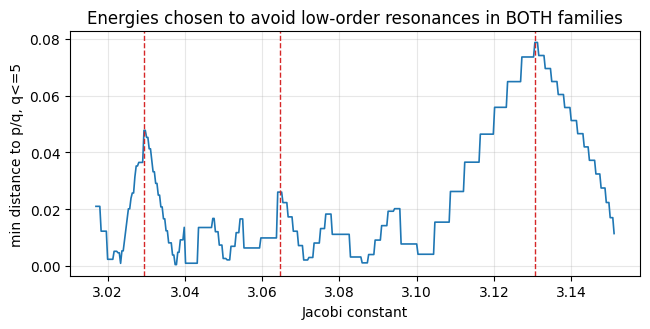

In [3]:
Q_MAX, N_ENERGY, MIN_SEP = 5, 3, 0.025

grid = np.linspace(C_LO + 1e-3, C_HI - 1e-3, 400)
def _nearest(p, c):
    f = halos[p]
    return f[int(np.argmin([abs(h['C'] - c) for h in f]))]
score = np.array([min(resonance_distance(_nearest(p, c)['rho'], q_max=Q_MAX)[0]
                      for p in halos) for c in grid])

pick = []
for i in np.argsort(-score):
    if all(abs(grid[i] - grid[j]) > MIN_SEP for j in pick):
        pick.append(i)
    if len(pick) == N_ENERGY:
        break
ENERGIES = sorted(float(grid[i]) for i in pick)

print(f"{'C':>10} " + " ".join(f"{p+' rho/2pi':>12} {p+' d(q<=5)':>11}" for p in halos))
for c in ENERGIES:
    row = f"{c:10.6f} "
    for p in halos:
        h = _nearest(p, c)
        row += f"{h['rho']/(2*np.pi):12.6f} {resonance_distance(h['rho'], Q_MAX)[0]:11.4f}"
    print(row)

fig, ax = plt.subplots(figsize=(6.6, 3.4))
ax.plot(grid, score, lw=1.2)
for c in ENERGIES:
    ax.axvline(c, color='tab:red', ls='--', lw=1)
ax.set_xlabel('Jacobi constant'); ax.set_ylabel(f'min distance to p/q, q<={Q_MAX}')
ax.set_title('Energies chosen to avoid low-order resonances in BOTH families')
ax.grid(alpha=.3); plt.tight_layout(); plt.show()

## 3. Torus family at each (family, energy), then densify

For each of the six combinations: seed a torus off the halo's centre eigenvector,
continue at fixed energy to a common target amplitude, then bisect gaps until the
interpolation error is under the floor.

`pin='C'` because that is the family in which amplitude varies at fixed energy —
`pin='rho'` holds the frequency ratio and traces a different curve through the same
two-parameter set.

**A common amplitude ceiling matters.** If one family reaches 900 km and another
300 km, amplitude becomes a proxy for family identity and the network can separate
the classes without learning any dynamics.

Checkpointed per combination.

In [4]:
A_TARGET_KM, N_STEPS, TARGET_GAP_KM, N_NODES, EPS_SEED = 400.0, 60, 12.3, 31, 1e-4

def build(point, C_target, tag):
    path = f'../data/families/{tag}.npz'
    if os.path.exists(path):
        mem = load_family(path)
        print(f"  {tag}: resumed {len(mem)} members", flush=True)
        return mem
    h = _nearest(point, C_target)
    orbit = dict(state0=h['state0'], period=h['period'])
    U, T, r = qpit.seed_from_halo(orbit, MU, N_NODES, EPS_SEED)
    with contextlib.redirect_stdout(io.StringIO()):
        seed = qpit.converge_torus(U, T, r, MU, tol=1e-12, itmax=20)
    assert seed['converged'], f"{tag} seed failed: {seed['code']}"
    with contextlib.redirect_stdout(io.StringIO()):
        fam = qpit.continue_torus_family(seed['U0'], seed['T'], seed['rho'], MU,
                                         pin='C', n_steps=N_STEPS,
                                         offgrid_every=0, verbose=False)
    mem = [m for m in fam['members'] if m['amplitude'] * LU <= A_TARGET_KM]
    print(f"  {tag}: halo C={h['C']:.6f} rho/2pi={h['rho']/(2*np.pi):.6f} -> "
          f"{len(mem)} members to {mem[-1]['amplitude']*LU:.1f} km "
          f"({fam['terminated']})", flush=True)
    mem, rep = densify(mem, MU, TARGET_GAP_KM, checkpoint=path,
                       offgrid=False, verbose=False)
    print(f"    densified to {len(mem)}, max gap {rep['max_gap_km']:.2f} km, "
          f"error {rep['error_km']*1000:.3f} m, failed {rep['n_failed']} "
          f"[{time.time()-t0:.0f}s]", flush=True)
    return mem

FAMILIES = {}
for fi, point in enumerate(('L1', 'L2')):
    for ei, C in enumerate(ENERGIES):
        tag = f"{point}_E{ei}"
        FAMILIES[(fi, ei, point, C, tag)] = build(point, C, tag)
print(f"\n{len(FAMILIES)} families built  [{time.time()-t0:.0f}s]")

  L1_E0: halo C=3.030335 rho/2pi=0.452252 -> 29 members to 0.3 km (n_steps)
    densified to 64, max gap 11.83 km, error 0.093 m, failed 0 [216s]
  L1_E1: halo C=3.066225 rho/2pi=0.307332 -> 14 members to 331.7 km (n_steps)
    densified to 44, max gap 11.79 km, error 0.093 m, failed 0 [448s]
  L1_E2: halo C=3.132121 rho/2pi=0.118094 -> 14 members to 303.2 km (n_steps)
    densified to 36, max gap 12.10 km, error 0.098 m, failed 0 [607s]
  L2_E0: halo C=3.029630 rho/2pi=0.449230 -> 29 members to 396.7 km (n_steps)
    densified to 48, max gap 12.26 km, error 0.100 m, failed 0 [833s]
  L2_E1: halo C=3.064421 rho/2pi=0.277323 -> 16 members to 369.4 km (n_steps)
    densified to 39, max gap 11.06 km, error 0.081 m, failed 0 [1038s]
  L2_E2: halo C=3.130505 rho/2pi=0.078704 -> 14 members to 395.3 km (n_steps)
    densified to 25, max gap 53.66 km, error 1.916 m, failed 9 [1433s]

6 families built  [1433s]


## 4. Sample and label

Three arms per family. Offsets are the backbone: distance drawn log-uniform and the
state *constructed* to realise it, so every sample doubles as a regression test of
the labeller. On-surface states anchor d = 0. Bundle offsets give off-centre-manifold
coverage.

**Expect measured/drawn ~ 1.000 for normal directions and ~ 0.84 for random ones.**
A random 6-D direction has a large tangential component the surface absorbs, which is
why the backbone projects both tangents out; the random arm is kept, declared, for
coverage. A normal-direction median away from 1.000 means the tangent projection is
wrong and the labels are biased.

In [5]:
N_OFFSET, N_SURFACE, N_BUNDLE = 2600, 400, 400
rng = np.random.default_rng(20260810)
blocks = []
for (fi, ei, point, C, tag), mem in FAMILIES.items():
    parts = [sample_offsets(mem, N_OFFSET, rng, d_lo_km=FLOOR_KM, d_hi_km=100.0),
             sample_on_surface(mem, N_SURFACE, rng),
             sample_bundle(mem, MU, N_BUNDLE, rng, d_lo_km=FLOOR_KM, d_hi_km=100.0)]
    D = label_and_pack(parts, mem, fi, ei, point, C)
    blocks.append(D)
    m = (D['source'] == 'offset') & (~D['random_dir']) & (~D['at_floor'])
    print(f"  {tag}: {len(D['d_km'])} states, normal-dir measured/drawn "
          f"median {np.median(D['d_km'][m]/D['d_drawn_km'][m]):.4f}  "
          f"[{time.time()-t0:.0f}s]", flush=True)

KEYS = [k for k in blocks[0] if k != 'states']
DATA = {'states': np.vstack([b['states'] for b in blocks])}
for k in KEYS:
    DATA[k] = np.concatenate([b[k] for b in blocks])
print(f"\n{DATA['states'].shape[0]} states total  [{time.time()-t0:.0f}s]")

  L1_E0: 3400 states, normal-dir measured/drawn median 0.9995  [1448s]
  L1_E1: 3400 states, normal-dir measured/drawn median 0.9998  [1460s]
  L1_E2: 3400 states, normal-dir measured/drawn median 1.0000  [1471s]
  L2_E0: 3400 states, normal-dir measured/drawn median 0.9919  [1484s]
  L2_E1: 3400 states, normal-dir measured/drawn median 0.9999  [1496s]
  L2_E2: 3400 states, normal-dir measured/drawn median 1.0000  [1513s]

20400 states total  [1513s]


## 5. Coverage diagnostics

Four things to check before trusting the file.

1. **log-d coverage flat** across the six decades. A peak means the construction is
   collapsing distances somewhere.
2. **Normal-direction measured/drawn = 1.000**; random ~0.84.
3. **Every (family, energy) cell populated** at similar amplitude range — otherwise
   amplitude or energy is a proxy for family identity.
4. **Group count >> intended test-set size.** `group_id` bins the base-point cell and
   is the key Week 11 must split on: samples from one cell are near-duplicates, and
   splitting on rows would put them on both sides of the train/test boundary.

normal dirs  n= 11769  measured/drawn median 0.9999
random dirs  n=  3769  measured/drawn median 0.8465
on-surface   n=  2400  at floor 2400
groups 6564, states 20400, median per group 2

 family          C      n       A range km    log10 d range
     L1   3.029398   3400     0.0-  373.4   -3.81-   2.00
     L1   3.064703   3400    14.9-  331.7   -3.81-   2.00
     L1   3.130607   3400    14.2-  303.2   -3.81-   2.00
     L2   3.029398   3400    11.4-  396.7   -3.81-   2.00
     L2   3.064703   3400    17.7-  369.4   -3.81-   2.00
     L2   3.130607   3400    23.9-  395.3   -3.81-   2.00


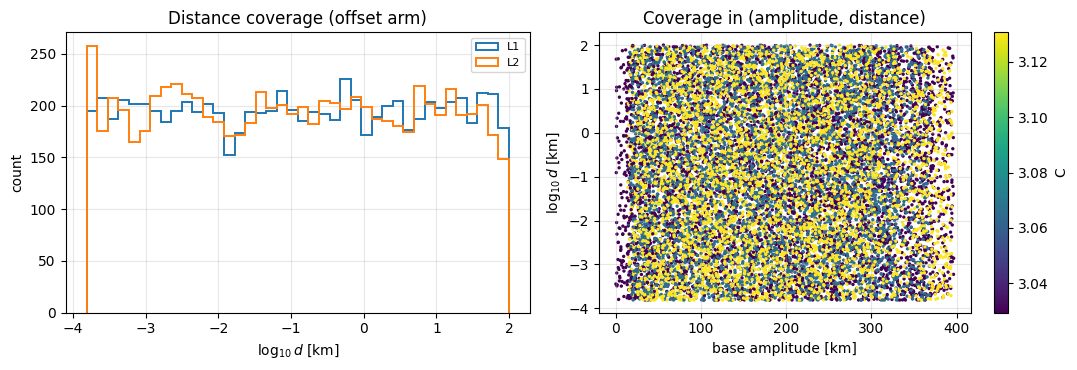

In [6]:
d = DATA
off = d['source'] == 'offset'
nrm, rnd = off & ~d['random_dir'] & ~d['at_floor'], off & d['random_dir'] & ~d['at_floor']
print(f"normal dirs  n={nrm.sum():6d}  measured/drawn median {np.median(d['d_km'][nrm]/d['d_drawn_km'][nrm]):.4f}")
print(f"random dirs  n={rnd.sum():6d}  measured/drawn median {np.median(d['d_km'][rnd]/d['d_drawn_km'][rnd]):.4f}")
print(f"on-surface   n={(d['source']=='surface').sum():6d}  at floor "
      f"{d['at_floor'][d['source']=='surface'].sum()}")
print(f"groups {len(np.unique(d['group_id']))}, states {len(d['d_km'])}, "
      f"median per group {np.median(np.bincount(np.unique(d['group_id'], return_inverse=True)[1])):.0f}")

print(f"\n{'family':>7} {'C':>10} {'n':>6} {'A range km':>16} {'log10 d range':>16}")
for fi in np.unique(d['family_id']):
    for ei in np.unique(d['energy_id']):
        s = (d['family_id'] == fi) & (d['energy_id'] == ei)
        if not s.any():
            continue
        print(f"{d['family'][s][0]:>7} {d['C'][s][0]:10.6f} {s.sum():6d} "
              f"{d['amplitude_km'][s].min():7.1f}-{d['amplitude_km'][s].max():7.1f} "
              f"{d['log_d_km'][s].min():7.2f}-{d['log_d_km'][s].max():7.2f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for fi in np.unique(d['family_id']):
    s = (d['family_id'] == fi) & off
    ax[0].hist(d['log_d_km'][s], bins=40, histtype='step', lw=1.4,
               label=d['family'][s][0])
ax[0].set_xlabel(r'$\log_{10} d$ [km]'); ax[0].set_ylabel('count')
ax[0].set_title('Distance coverage (offset arm)'); ax[0].legend(fontsize=8)
ax[0].grid(alpha=.3)
sc = ax[1].scatter(d['amplitude_km'][off], d['log_d_km'][off], s=2,
                   c=d['C'][off], cmap='viridis')
ax[1].set_xlabel('base amplitude [km]'); ax[1].set_ylabel(r'$\log_{10} d$ [km]')
ax[1].set_title('Coverage in (amplitude, distance)'); ax[1].grid(alpha=.3)
plt.colorbar(sc, ax=ax[1], label='C')
plt.tight_layout(); plt.show()

## 6. Save

`score_C` is the regression target (log10 km, floored at the measured 0.155 m).
`label_B` is its thresholded readout — reported, not trained on. The threshold is a
free parameter, so Week 11 should report accuracy **as a curve against tolerance**
rather than a single number.

Provenance travels with the data: energies, floor, sampler counts, family sizes and
their gap bounds. A dataset whose accuracy claim cannot be traced to a spacing and a
floor is not reproducible.

In [7]:
LABEL_B_KM = 1.0        # arbitrary by construction: report the curve, not this
meta = dict(
    energies=np.array(ENERGIES), floor_km=FLOOR_KM, label_B_km=LABEL_B_KM,
    target_gap_km=TARGET_GAP_KM, A_target_km=A_TARGET_KM, q_max=Q_MAX,
    n_offset=N_OFFSET, n_surface=N_SURFACE, n_bundle=N_BUNDLE, mu=MU,
    family_tags=np.array([k[4] for k in FAMILIES]),
    family_sizes=np.array([len(v) for v in FAMILIES.values()]),
    family_max_gap_km=np.array([np.diff(sorted(m['amplitude'] for m in v)).max() * LU
                                for v in FAMILIES.values()]))
np.savez_compressed('../data/qpit_dataset_w10.npz',
                    score_C=DATA['log_d_km'], label_B=DATA['d_km'] <= LABEL_B_KM,
                    **{k: DATA[k] for k in ['states', 'd_km', 'at_floor',
                                            'd_drawn_km', 'source', 'random_dir',
                                            'amplitude_km', 'gap', 'alpha', 'theta',
                                            'group_id', 'family_id', 'family',
                                            'energy_id', 'C', 'jacobi']},
                    **meta)
print(f"saved {DATA['states'].shape[0]} states -> ../data/qpit_dataset_w10.npz")
print(f"max family gap {meta['family_max_gap_km'].max():.2f} km -> "
      f"interp error {interp_error_km(meta['family_max_gap_km'].max())*1000:.3f} m")
print(f"[{time.time()-t0:.0f}s total]")

saved 20400 states -> ../data/qpit_dataset_w10.npz
max family gap 53.66 km -> interp error 1.916 m
[1513s total]


## What this is, and what it is not

**Is.** ~21k labelled states across two families and three energies, with a
continuous distance target accurate to ~0.155 m — a floor set by the tori's own
determination, not by anything adjustable. Both `family_id` and `C` vary, so neither
is the constant column a single-family single-energy dataset would have left in
Week 11's feature list.

**Is not.** There is no resonance arm. Two attempts to build one produced no usable
negatives: at 2/7 the resonance was too thin to detect at all, and at 1/4 the
extrapolation-error budget collapsed from 75 km to zero as the family approached, so
failures there cannot be separated from bad seeds. The 1/4 family is saved and
characterised as physics; it is not in this dataset as labels.

**Next (Week 11).** Grouped train/test split on `group_id`. Feature representation.
Baseline before network: a model on (distance from L1/L2, C) alone should do poorly,
and if it does not, the sampling has left a location shortcut in.